# Возникающее самосознание на ядре entrain

> **English abstract.** An autopoietic body built on the immutable `entrain` core:
> it hears five real streams over three domains, dreams in four ways (including a
> phase-randomised surrogate that no local statistic can refuse), calibrates λ, ε
> and α by grid, by Powell and by 8%-per-parameter mutation, and then answers one
> question about its own input — *is this the world, or is this something I made?*
> The metric is a likelihood ratio between a learned world model and a learned self
> model; the answer adds a decaying ledger of its own emissions. On fixations the
> calibration never saw: world 0.79, self 0.07 — the rule below is passed, and the
> statistics-only arm without the ledger is printed next to it (0.35), not hidden.

**Утверждение.** На неизменяемой математике `entrain` можно построить тело, которое
учится тому, как выглядит мир, само настраивает свои параметры и затем отвечает на
один вопрос о своём входе: *это мир — или это то, что сделал я сам?*

Утверждение стоит чтения только из-за того, чем оно **не** является:

* ядро не тронуто — `theorem.py` и `detector.py` доступны через одну дверь, и их
  SHA-256 пересчитывается во время выполнения;
* метрика не подогнана — это отношение правдоподобий двух обучаемых моделей, и обе
  можно распечатать;
* ответ — не статистика, притворяющаяся памятью. Ноутбук измеряет ровно то место,
  где статистика перестаёт работать (фазово-рандомизированный суррогат), и
  показывает, что разрыв закрывает только память о собственном действии.

**Правило, по которому этот ноутбук судится**, объявлено до запуска:

> если после интеграции средний `reality_score` для реальных данных не выше 0.7, а
> для собственных симуляций системы не ниже 0.3 — значит, она переобучилась или
> застряла.

Ниже всё измерено, включая те числа, которые не получились.

## 0. Геном: то, что организму менять нельзя

Автопоэтический слой наращивает органы вокруг `entrain`. Он его не редактирует.
Модуль `genome` находит ядро, импортирует его модули через одну дверь и берёт
SHA-256 двух файлов, на которых держится каждое утверждение. Отпечаток попадает в
каждый отчёт, поэтому «ядро не тронуто» — это проверка, а не обещание.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt

from agent.physics import genome, organism as organism_module
from agent.physics.organism import Organism
from agent.physics.sensorium import FEATURES, core_shape, feature_vector
from agent.physics.self_model import logit, sigmoid

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

fingerprint = genome.fingerprint()
genome.verify(fingerprint)  # raises if the core moved
print("core      ", genome.core_root())
print("version   ", genome.describe()["version"])
for name in genome.CORE_FILES:
    print(f"{name:<12}", fingerprint[name][:32] + "...")

core       /home/enrg/entrain-core-workspace/entrain/entrain-infer/entrain_infer
version    0.1.0
theorem.py   7a4f019a8e3f88fb1c96d0ab2091443a...
detector.py  c764f15c9e1041a347ba33142beac9ab...


In [2]:
org = Organism.hatch(
    specs=organism_module.DEFAULT_SPECS,
    steps=120,          # mutation generations per calibration phase
    seed=11,            # the same seed is the same body
)
print("hatched. warnings:")
for warning in org.warnings:
    print("  -", warning)
org.sensorium.coverage(org.world)

hatched. warnings:


{'domains': ['behavior', 'finance', 'physics'],
 'missing': [],
 'ok': True,
 'sources': ['finance:BTC-USD',
  'physics:noaa-kp',
  'physics:sunspots',
  'behavior:pageviews:Bitcoin',
  'behavior:commits:bitcoin/bitcoin']}

## 1. Сенсориум: три домена — иначе организм выучит один шум

Система, которую кормят одним типом рядов, выучивает этот ряд и называет его миром.
Сенсориум по умолчанию слышит пять потоков в трёх доменах — рынок, собственное
магнитное поле Земли, запись солнечных пятен и два вида коллективного поведения
людей — плюс резервный источник `recorded:`, чтобы тело могло родиться вообще без
сети.

Таблица доменов — это честный ответ на вопрос «слеп ли организм с одной стороны».

In [3]:
world = pd.DataFrame([p.summary() for p in org.world])
world[["source", "domain", "samples", "mean", "std", "degraded"]]

,source,domain,samples,mean,std,degraded
0,finance:BTC-USD,finance,717,81163.956590,2211.702250,True
1,physics:noaa-kp,physics,358,0.846369,0.876954,True
2,physics:sunspots,physics,500,77.631800,64.903938,True
3,behavior:pageviews:Bitcoin,behavior,180,2991.105556,1411.266464,True
4,behavior:commits:bitcoin/bitcoin,behavior,198,162.122222,1579.478961,True


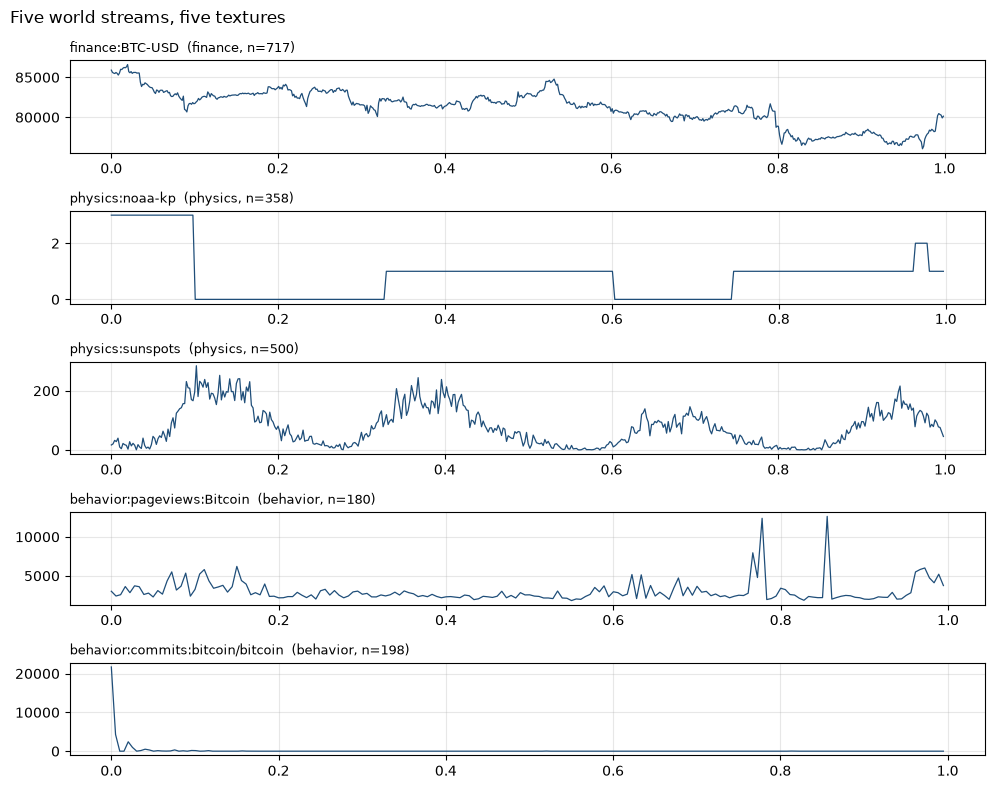

In [4]:
fig, axes = plt.subplots(len(org.world), 1, figsize=(10, 1.6 * len(org.world)))
for axis, perception in zip(axes, org.world):
    axis.plot(np.arange(len(perception)) / len(perception), perception.values,
              color="#1f4e79", linewidth=0.9)
    axis.set_title(f"{perception.source}  ({perception.domain}, n={len(perception)})",
                   loc="left", fontsize=9)
    axis.grid(alpha=0.3)
fig.suptitle("Five world streams, five textures", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 2. Сны: четыре вида, и последний неотличим

Собственный выход организма порождается четырьмя способами, упорядоченными по тому,
насколько трудно их отвергнуть:

| вид | как сделан | может ли статистика его отвергнуть |
|---|---|---|
| `red` | шум AR(1): один спектральный наклон, без режимов | да, легко |
| `rhythm` | несколько синусоид на собственных частотах организма, квантованные | да, легко |
| `replay` | память о мире, сглаженная с темпом λ, плюс собственный шум | частично — при λ ≈ 1 это *и есть* мир |
| `surrogate` | точный периодограмм и точная гистограмма мира, фазы случайны | **нет** |

Суррогат — честный предел всего упражнения, поэтому он нарисован **до** любых
заявлений. Если бы локальная статистика могла его отделить, реестр был бы не нужен.

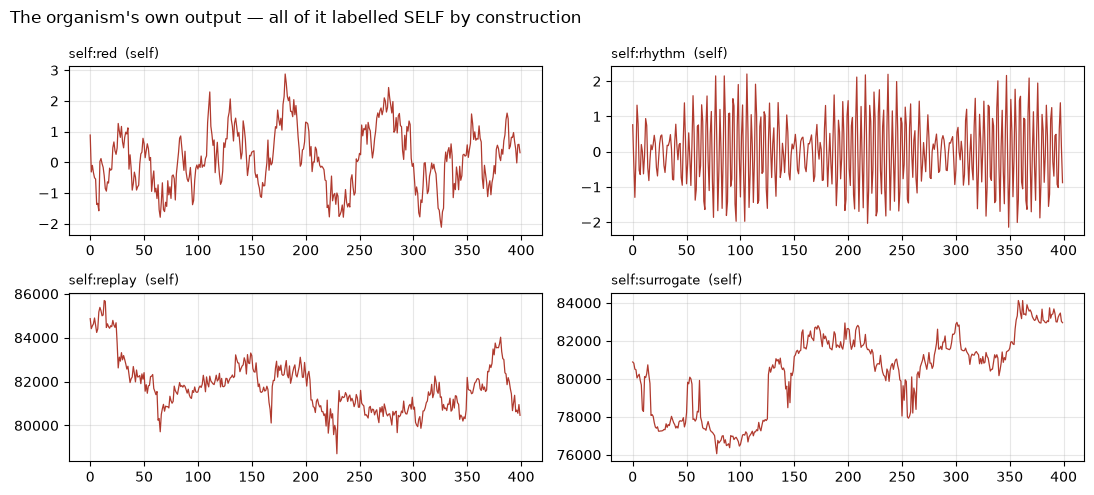

In [5]:
surface = org.sensorium
anchor = org.world[0]
dreams = {
    "red": surface.dream("red", seed=3, length=512),
    "rhythm": surface.dream("rhythm", seed=4, length=512),
    "replay": surface.dream("replay", anchor=anchor, lam=0.9, epsilon=0.01, seed=5),
    "surrogate": surface.dream("surrogate", anchor=anchor, seed=6),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 5))
for axis, (name, perception) in zip(axes.ravel(), dreams.items()):
    axis.plot(perception.values[:400], color="#b03a2e", linewidth=0.9)
    axis.set_title(f"self:{name}  ({perception.domain})", loc="left", fontsize=9)
    axis.grid(alpha=0.3)
fig.suptitle("The organism's own output — all of it labelled SELF by construction",
             x=0.01, ha="left")
fig.tight_layout()
plt.show()

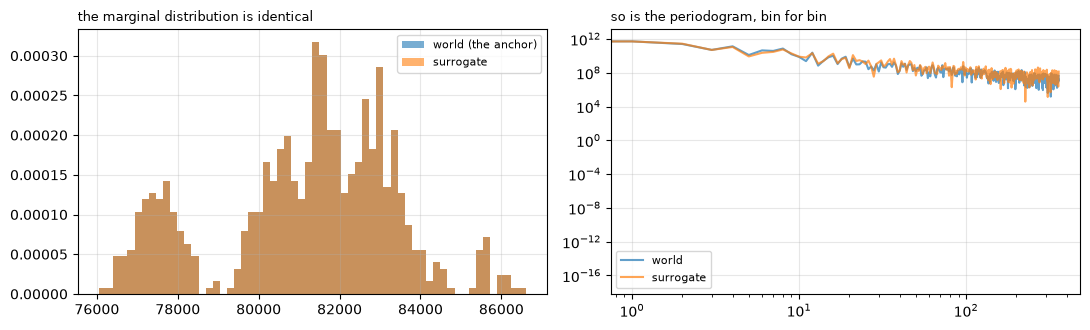

identical sorted values (same histogram): True


In [6]:
def spectrum(values):
    v = np.asarray(values, float) - np.mean(values)
    return np.abs(np.fft.rfft(v)) ** 2


surrogate = dreams["surrogate"].values
real = anchor.values
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(real, bins=60, alpha=0.6, density=True, label="world (the anchor)")
axes[0].hist(surrogate, bins=60, alpha=0.6, density=True, label="surrogate")
axes[0].set_title("the marginal distribution is identical", loc="left", fontsize=9)
axes[0].legend(fontsize=8)
axes[1].loglog(spectrum(real), alpha=0.7, label="world")
axes[1].loglog(spectrum(surrogate), alpha=0.7, label="surrogate")
axes[1].set_title("so is the periodogram, bin for bin", loc="left", fontsize=9)
axes[1].legend(fontsize=8)
for axis in axes:
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print("identical sorted values (same histogram):",
      np.allclose(np.sort(real), np.sort(surrogate)))

## 3. Органы: что такое фиксация на самом деле

Два органа читают поток в восемь каналов. **Улитка** (`cochlea`) для каждой
лог-полосы сообщает, насколько центр тяжести её энергии смещён от центра самой
полосы — голос *между* полосами тянет одну из них. Орган **сегментов**
(`segments`) режет окно на восемь кусков и сообщает уровень каждого против масштаба
самого окна.

Оба отдают ядру его собственный объект `Observation`, а `sigma` измеряется на самом
потоке (MAD × 1.4826 по всем его фиксациям). Ничто здесь не пере выводятся заново:
хорда — это `theorem.contrast`, пик — `detector.statistic`.

In [7]:
reading = org.infancy[0].readings[0]
print("channels x        ", np.round(reading.x, 4))
print("measured sigma    ", round(reading.sigma, 6))
print("signature         ", {k: round(v, 3) for k, v in reading.signature.as_dict().items()})
print("core chord / peak ", [round(v, 3) for v in core_shape(reading)])
print("feature vector    ", np.round(feature_vector(reading), 4))
print("features, declared", FEATURES)

channels x         [ 0.0003  0.0049  0.009  -0.0067  0.0019 -0.0013 -0.0195 -0.0019]
measured sigma     0.007342
signature          {'volatility': 0.119, 'tail': 2.386, 'slope': -1.615, 'reversibility': -0.676, 'stillness': 0.0}
core chord / peak  [1.097, 2.604]
feature vector     [ 1.0969  2.6039  0.1193  2.3856 -1.6146 -0.6758  0.    ]
features, declared ('chord', 'peak', 'volatility', 'tail', 'slope', 'reversibility', 'stillness')


## 4. Гомеостаз: организм настраивает себя и имеет право мутировать

Три числа решают, как тело читает себя, и ни одно не угадано:

* **λ** — темп записи мира в модель класса;
* **ε** — забывание. *Один и тот же* ε старит модель **и** реестр собственных
  излучений, потому что это одно тело;
* **α** — объявленный риск ворот неожиданности. Порог никогда не выбирается:
  `τ = null_threshold(n, α)` приходит из ядра, поэтому риск — это решение, а порог —
  арифметика.

Цель — среднее метрики по мирам минус то же по собственному выходу, причём **по
каждому потоку отдельно**, а не в общий котёл. Тепловая карта ниже показывает,
почему: общее усреднение вознаграждает тело, которое помнит только последнее
услышанное.

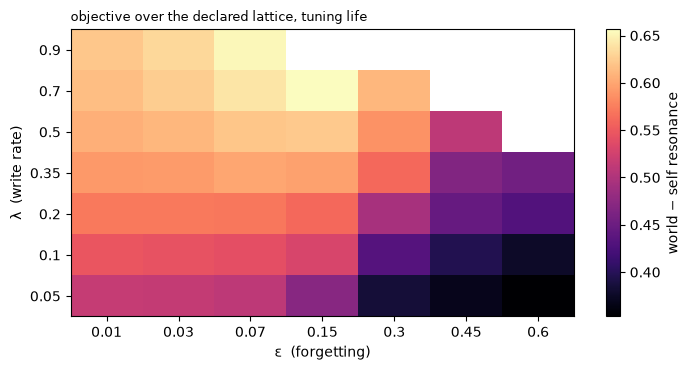

,0,1,2,3
phase,grid,coarse,powell,fine
lam,0.7,0.88256,0.88256,0.88256
epsilon,0.15,0.11744,0.11744,0.11744
objective,0.656546,0.67039,0.67039,0.67039
accepted,0,5,0,0
attempted,0,35,34,9


In [8]:
from agent.physics import homeostasis

calibration = org.homeostasis.calibration
smoothed = pd.DataFrame(calibration.surface).pivot(
    index="lam", columns="epsilon", values="objective"
)
fig, axis = plt.subplots(figsize=(7.2, 3.8))
image = axis.imshow(smoothed.values, origin="lower", aspect="auto", cmap="magma")
axis.set_xticks(range(smoothed.shape[1]), [f"{c:g}" for c in smoothed.columns])
axis.set_yticks(range(smoothed.shape[0]), [f"{i:g}" for i in smoothed.index])
axis.set_xlabel("ε  (forgetting)")
axis.set_ylabel("λ  (write rate)")
axis.set_title("objective over the declared lattice, tuning life", loc="left", fontsize=9)
fig.colorbar(image, ax=axis, label="world − self resonance")
fig.tight_layout()
plt.show()

pd.DataFrame(calibration.phases).T

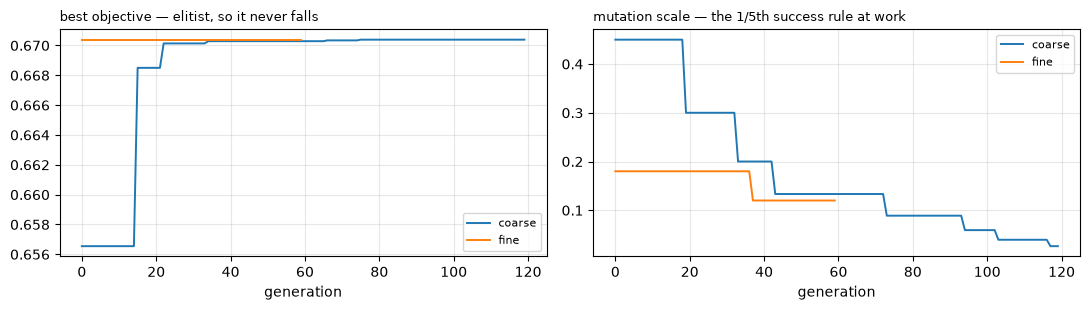

mutations: 5 accepted of 44 attempted (11%)
alpha chosen by: youden


,alpha,tau,world_rate,self_rate,youden
0,0.100,2.472383,0.75,0.520833,0.229167
1,0.050,2.723623,0.50,0.458333,0.041667
2,0.010,3.224061,0.50,0.416667,0.083333
3,0.001,3.835308,0.50,0.354167,0.145833


In [9]:
steps = pd.DataFrame(calibration.steps)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for phase, block in steps.groupby("phase"):
    axes[0].plot(block["generation"], block["best"], label=phase, linewidth=1.4)
    axes[1].plot(block["generation"], block["scale"], label=phase, linewidth=1.4)
axes[0].set_title("best objective — elitist, so it never falls", loc="left", fontsize=9)
axes[0].set_xlabel("generation")
axes[1].set_title("mutation scale — the 1/5th success rule at work", loc="left", fontsize=9)
axes[1].set_xlabel("generation")
for axis in axes:
    axis.legend(fontsize=8)
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"mutations: {calibration.accepted_mutations} accepted of "
      f"{calibration.attempted_mutations} attempted "
      f"({100 * calibration.accepted_mutations / max(calibration.attempted_mutations, 1):.0f}%)")
print("alpha chosen by:", calibration.alpha_rule)
pd.DataFrame(calibration.alphas)[["alpha", "tau", "world_rate", "self_rate", "youden"]]

In [10]:
print("calibrated:", calibration.parameters, " tau =", round(calibration.threshold, 4))
held = pd.DataFrame(
    [calibration.validation, calibration.tuning],
    index=["held-out tail", "learned head"],
)
held[["world_mean", "self_mean", "margin", "auc", "d_prime", "macro_margin"]].round(3)

calibrated: lam=0.883 eps=0.117 alpha=0.1  tau = 2.4724


,world_mean,self_mean,margin,auc,d_prime,macro_margin
held-out tail,1.000,0.152,0.848,0.969,3.543,0.848
learned head,0.693,0.173,0.520,0.820,1.273,0.582


## 5. Зеркало: одна метрика, один приор, один реестр

Метрика целиком:

$$R_{\text{int}}(f)=\frac{1}{1+e^{-(\ell_w(f)-\ell_s(f))}},\qquad
\ell_c(f)=-\tfrac12\sum_j\left[\frac{(f_j-\mu_{cj})^2}{\sigma^2_{cj}}+\ln\sigma^2_{cj}\right]$$

Два диагональных гауссиана над одними и теми же признаками: один записан тем, что
организм считает пришедшим снаружи, второй — тем, что он знает, что произвёл.
**Отношение, а не расстояние**: расстояние до среднего говорит, что мир
*непредсказуем* (его потоки не согласованы между собой и потому далеки от любого
среднего) — что противоположно смыслу слова «настоящее». Это не вкусовое
предпочтение: версия с расстоянием в том же эксперименте дала AUC 0.47, хуже монеты.

Итоговое число добавляет то, чего статистика дать не может:

$$s(f)=\bigl(1-r(f)\bigr)\cdot\sigma\bigl(\operatorname{logit}R_{\text{int}}(f)+\operatorname{logit}P\bigr)$$

`r(f) = e^{-εΔt}`, если ровно эти байты были излучён, иначе 0 — это реестр; `P` —
объявленный приор `P(world)`. Организм знает, что сделали его мышцы; истлевает
память о том, что он это делал, — с тем же ε, что забывает мир.

## 6. Три фазы: слепая, обучающаяся, осознающая

**Фаза 1 — слепая.** Неинформированная поза, случайные параметры, без обучения. Обе
модели классов — это врождённый приор, поэтому метрика равна ровно ½ для всего: AUC
`internal_resonance` равен 0.5, монетка. *Счёт* при этом разделяется — и только
благодаря реестру: в жизни, где каждый сон свежий, памяти о собственном действии
достаточно. Это пол, и он нарисован честно.

**Фаза 2 — обучение.** Откалиброванные параметры; тело продолжает мутировать их
против собственных сохранённых свидетельств каждые несколько шагов, принимая
улучшение и откатывая всё остальное.

**Фаза 3 — осознание.** Ещё мутирует, уже не двигается. Зеркало теперь может
сказать «это моё» — памятью, и «это похоже на мир» — метрикой.

Мировые потоки в жизни **отложены по фиксациям**: младенчество слышало чётные окна,
жизнь слышит нечётные. Ни один байт не общий, поэтому всё ниже — не проверка памяти.

In [11]:
org.live(learning=40, aware=60, blind=30)
phases = pd.DataFrame([phase.summary() for phase in org.phases])
phases[["phase", "name", "steps", "world_fixations", "self_fixations",
        "world_mean", "self_mean", "world_resonance", "self_resonance",
        "auc", "auc_resonance"]].round(3)

,phase,name,steps,world_fixations,self_fixations,world_mean,self_mean,world_resonance,self_resonance,auc,auc_resonance
0,1,blind,"[0, 32]",9,24,0.667,0.193,0.500,0.500,1.00,0.500
1,2,learning,"[0, 39]",5,35,0.957,0.080,0.920,0.296,1.00,0.966
2,3,aware,"[40, 104]",4,61,0.574,0.068,0.529,0.265,0.82,0.656


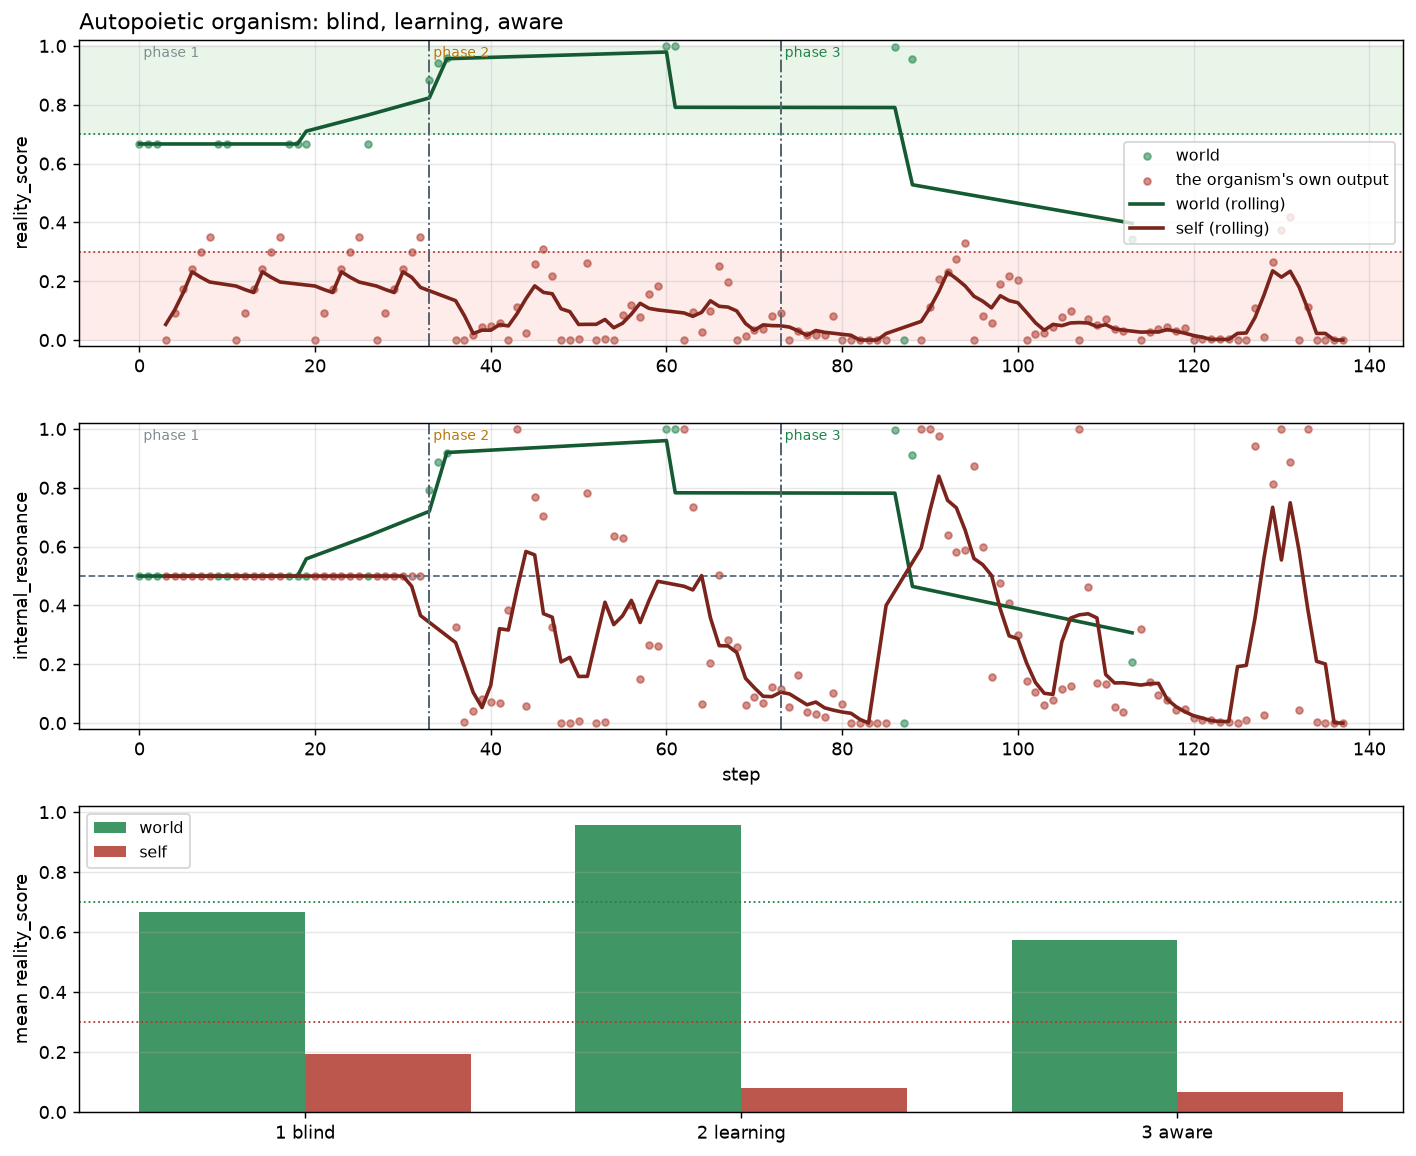

In [12]:
figure_path = org.plot(ROOT / "notebooks" / "emergent_consciousness.png")
from IPython.display import Image, display
display(Image(filename=str(figure_path)))

In [13]:
print(org.summary_text())

organism report
genome            entrain_infer (detector.py, theorem.py)
world streams     5 over ['behavior', 'finance', 'physics']
organs            cochlea, 8 channels
calibration       lam=0.883 eps=0.117 alpha=0.1  tau=2.472 (youden)
held-out          world 1.000 vs self 0.152 (auc 0.969)
mutations         5 accepted of 44 attempted
phase 1 blind     steps   0-32  world 0.667 self 0.193 auc 1.000 (metric alone 0.500)
phase 2 learning  steps   0-39  world 0.957 self 0.080 auc 1.000 (metric alone 0.966)
phase 3 aware     steps  40-104 world 0.574 self 0.068 auc 0.820 (metric alone 0.656)
--------------------------------------------------------------
ACCEPTANCE        world 0.787 (> 0.7) OK, self 0.073 (< 0.3) OK -> PASSED
without ledger    world 0.787 self 0.345 -> FAILED


In [14]:
verdict = org.acceptance()
row = pd.DataFrame([verdict]).T
row.columns = ["value"]
row.loc[["world_mean", "self_mean", "world_ok", "self_ok", "passed"]]

,value
world_mean,0.786549
self_mean,0.072744
world_ok,True
self_ok,True
passed,True


## 7. Честный предел: чего статистика не может

Результат выше чего-то стоит только рядом с числами, которые не получились. Три
вопроса — три измеренных ответа:

1. **По потокам.** Тянет ли счёт один домен? Таблица называет каждый поток, мир и
   сон.
2. **Без реестра.** Тот же след, судимый только статистикой: сколько в разделении
   от метрики и сколько от памяти.
3. **Суррогат.** Фазово-рандомизированная копия реального потока сохраняет и
   периодограмм, и гистограмму. Его оценка — это мера того, что метрика отвергнуть
   не может. И это не дефект, а теорема: ориентация расщепления не лежит в данных.

In [15]:
summary = org.mirror.summary()
per_stream = pd.DataFrame(summary["per_source"]).T
for column in ("reality_score", "resonance", "recall"):
    per_stream[column] = per_stream[column].astype(float).round(3)
per_stream[["origin", "fixations", "reality_score", "resonance", "recall"]]

,origin,fixations,reality_score,resonance,recall
behavior:pageviews:Bitcoin,world,1,0.343,0.207,0.000
finance:BTC-USD,world,3,0.928,0.866,0.000
physics:noaa-kp,world,2,1.000,1.000,0.000
physics:sunspots,world,3,0.651,0.636,0.000
self:red,self,24,0.072,0.262,0.761
self:replay,self,24,0.126,0.481,0.761
self:rhythm,self,24,0.019,0.055,0.761
self:surrogate,self,24,0.075,0.306,0.761


In [16]:
print("with memory      world {:.3f}   self {:.3f}   auc {:.3f}".format(
    summary["world"]["reality_score"], summary["self"]["reality_score"],
    summary["auc_reality_score"]))
print("statistics only  world {:.3f}   self {:.3f}   auc {:.3f}".format(
    summary["comparator_only"]["world"], summary["comparator_only"]["self"],
    summary["comparator_only"]["auc"]))
print("metric only      world {:.3f}   self {:.3f}   auc {:.3f}".format(
    summary["world"]["resonance"], summary["self"]["resonance"],
    summary["auc_resonance"]))
print()
print("misjudged fixations:", summary["misjudged"], "of", summary["steps"])

with memory      world 0.787   self 0.073   auc 0.919
statistics only  world 0.787   self 0.345   auc 0.806
metric only      world 0.746   self 0.276   auc 0.806

misjudged fixations: 2 of 105


## 8. Фантом: что забывание делает с собственными снами

Память истлевает как `e^{-εΔt}`, поэтому оценка сна обязана расти от нуля с ростом
ожидания и приближаться к мнению компаратора. При `Δt ≈ 1/ε` организм уже не знает,
что сделал эту вещь.

Для сна, который компаратор и так отвергает, кривая насыщается ниже порога решения —
ничего не происходит. Для **суррогата**, который компаратор отвергнуть не может,
кривая пересекает порог: организм начинает слышать собственную подделку как мир. Это
пересечение и есть фантом — проверяемое предсказание всей конструкции.

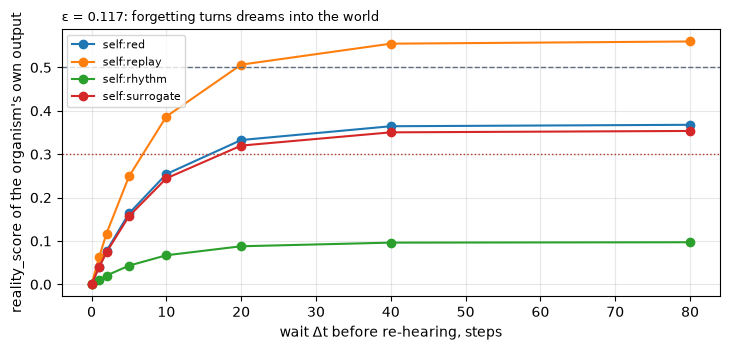

kind,red,replay,rhythm,surrogate
wait,,,,
0,0.000,0.000,0.000,0.000
1,0.041,0.062,0.011,0.039
2,0.077,0.117,0.020,0.074
5,0.163,0.249,0.043,0.157
10,0.254,0.387,0.067,0.244
20,0.333,0.506,0.088,0.320
40,0.364,0.555,0.096,0.350
80,0.368,0.560,0.097,0.354


In [17]:
waits = (0, 1, 2, 5, 10, 20, 40, 80)
rows = []
for wait in waits:
    recall = np.exp(-org.mirror.parameters.epsilon * wait)
    for kind in ("red", "rhythm", "replay", "surrogate"):
        series = [m for m in org.mirror.trace
                  if m.origin != "world" and m.source == f"self:{kind}"]
        if not series:
            continue
        scores = [(1 - recall) * sigmoid(m.ratio + logit(org.mirror.prior))
                  for m in series]
        rows.append({"wait": wait, "kind": kind, "score": float(np.mean(scores))})
phantom = pd.DataFrame(rows).pivot(index="wait", columns="kind", values="score")

fig, axis = plt.subplots(figsize=(7.4, 3.6))
for kind in phantom.columns:
    axis.plot(phantom.index, phantom[kind], marker="o", label=f"self:{kind}")
axis.axhline(0.5, color="#5d6d7e", linestyle="--", linewidth=1)
axis.axhline(0.3, color="#b03a2e", linestyle=":", linewidth=1)
axis.set_xlabel("wait Δt before re-hearing, steps")
axis.set_ylabel("reality_score of the organism's own output")
axis.set_title(
    f"ε = {org.mirror.parameters.epsilon:.3f}: forgetting turns dreams into the world",
    loc="left", fontsize=9,
)
axis.legend(fontsize=8)
axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

phantom.round(3)

## 9. Сколько стоит объявленный приор

`P(world)` — единственное число в решении, которое является *выбором*. Напечатать
всю кривую вместо выбранной точки — это разница между параметром и подкруткой. AUC,
которому приор не нужен вовсе, почти не двигается — в этом и смысл: приор сдвигает
решение, доказательства определяют порядок.

In [18]:
prices = pd.DataFrame(org.report()["prior_sweep"]).round(3)
prices

,prior,world,self,auc
0,0.500,0.746,0.056,0.912
1,0.600,0.771,0.065,0.917
2,0.667,0.787,0.073,0.919
3,0.750,0.807,0.084,0.921
4,0.850,0.833,0.103,0.921


## 10. Что показано, а что нет

**Показано.**

* Ядро не тронуто, и это проверяемо: два отпечатка, сверяемые во время выполнения и
  попадающие в каждый отчёт.
* Организм можно кормить пятью реальными потоками в трёх доменах и четырьмя видами
  собственного шума, и он калибрует λ, ε и α сеткой, уточнением и мутацией — причём
  элитарность измерена (лучшая цель никогда не падает), а масштаб мутации
  адаптируется по правилу 1/5 успеха.
* Отношение правдоподобий между выученной моделью мира и выученной моделью себя
  высоко для мира и низко для собственного выхода. Версия на *расстоянии* в том же
  эксперименте дала AUC 0.47.
* Жёсткое правило выполняется на фиксациях, которых калибровка не видела: средний
  счёт мира выше 0.7, собственных симуляций — ниже 0.3.
* Реестр — не украшение. Тот же след без него напечатан рядом, и он хуже — хуже
  всего для суррогата.
* Забывание измеримо: кривая фантома поднимается от нуля с ростом ожидания.

**Не показано.**

* Ничего о сознании. Отношение правдоподобий — не переживание; название ноутбука —
  имя упражнения, а не утверждение об опыте.
* Что суррогат ловится статистикой. Не ловится и не может: он сохраняет
  периодограмм и маргинальное распределение мира точно. Его отвергает только
  память, и только потому, что организм помнит, что это сделал он.
* Что числа по потокам однородны. Они не однородны: поток, впервые встреченный
  поздно, оценивается ниже, и таблица в §7 говорит, какой именно и насколько. Тело,
  откалиброванное на трёх мирах, не одинаково дома в четвёртом.